# Capítulo 1 — Propiedades de los fluidos

Propiedades del gas natural, del aceite saturado y bajosaturado y del agua, con el procedimiento del libro para
elegir correlaciones y ajustarlas a los datos de laboratorio. Son la base de todos los capítulos siguientes:
el flujo multifásico (caps. 5 a 9) las necesita en cada punto de la tubería.

> **Fuente.** Métodos y datos de *Transporte de Hidrocarburos por Ductos*, F. Garaicochea P.,
> C. Bernal H. y O. López O. (CIPM, 1991; reed. 2022), verificados contra la tesis UNAM de 1990 que
> le dio origen (Bernal y López, asesor Garaicochea). Los enunciados están **parafraseados**; consulte la
> obra original para el texto completo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ductos.pvt_gas import Gas, pseudocriticas, wichert_aziz, z_dpr, z_dpr_sustitucion
from ductos.pvt_aceite import (AceiteNegro, gamma_gas_disuelto, rs_lasater, rs_vazquez, pb_vazquez,
                               bo_oistein, gamma_aceite)
from ductos.pvt_agua import (bw_saturada, densidad_agua_saturada, viscosidad_agua_saturada,
                             tension_superficial_agua_gas, rsw, compresibilidad_agua)

## 1.1 Condiciones estándar y datos del problema

En México las condiciones estándar son 14.69 lb/pg² abs y 60 °F. Las correlaciones dan valores aproximados; el
procedimiento del libro consiste en compararlas contra el laboratorio en el punto de burbujeo, elegir las que mejor
ajustan y corregirlas con un factor $C = \\text{laboratorio}/\\text{calculado}$.

### Ejemplo 1.1 — datos

* Agua con 0.18 % de NaCl; gas húmedo con γg = 0.85 (una etapa de separación), 2.87 % de CO₂ y 23.27 % de H₂S.
* Aceite de 30 °API, RGA de 750 pie³/bl, separador a 120 lb/pg² abs y 75 °F.
* Laboratorio (separación instantánea): Bofb = 1.455, Rsfb = 750 pie³/bl, pb = 3300 lb/pg² abs a 220 °F.
* Condiciones de interés: 2000 lb/pg² abs y 200 °F.

## 1.3 Selección de correlaciones para el aceite saturado (Tabla 1)

En el punto de burbujeo todo el gas está disuelto, así que γgd = γg = 0.85. Para Vázquez se usa la γg normalizada a una
separación de 100 lb/pg² man (Ec. 1.35).

In [2]:
aceite = AceiteNegro(api=30, gamma_g=0.85, R=750, p_sep=120, t_sep=75)
print(f"γo = {aceite.gamma_o:.4f}   γgs (Vázquez) = {aceite.gamma_gs:.5f}   [libro: 0.85222]")
tabla1 = pd.DataFrame(aceite.calibrar(pb_lab=3300, rsfb_lab=750, bofb_lab=1.455, t_b=220)).set_index("correlación")
libro_t1 = pd.DataFrame({"Rs libro": [736, 610, 653, 752], "Bo libro": [1.4723, 1.3729, 1.4324, None],
                         "pb libro": [3352, 3626, 2971, 3299]},
                        index=["Standing", "Vázquez", "Oistein", "Lasater"])
tabla1.join(libro_t1).round(4)

γo = 0.8762   γgs (Vázquez) = 0.85222   [libro: 0.85222]


,Rs,C_Rs,pb,C_pb,Bo,C_Bo,Rs libro,Bo libro,pb libro
correlación,,,,,,,,,
Standing,735.8991,1.0192,3352.3986,0.9844,1.4723,0.9882,736,1.4723,3352
Vázquez,676.5987,1.1085,3625.8671,0.9101,1.3729,1.0598,610,1.3729,3626
Oistein,652.5583,1.1493,2971.1999,1.1107,1.4324,1.0158,653,1.4324,2971
Lasater,751.8971,0.9975,3298.6889,1.0004,NaN,NaN,752,NaN,3299


In [3]:
print(f"Elegidas: pb -> {aceite.corr_pb} (C = {aceite.c_pb:.4f}), Rs -> {aceite.corr_rs} (C = {aceite.c_rs:.4f}), "
      f"Bo -> {aceite.corr_bo} (C = {aceite.c_bo:.4f})")
print(f"Factor de la Ec. 1.2 para que γgd = γg en pb: {aceite.c_gd:.4f}   [libro: 1.1042]")

Elegidas: pb -> Lasater (C = 1.0004), Rs -> Lasater (C = 0.9975), Bo -> Standing (C = 0.9882)
Factor de la Ec. 1.2 para que γgd = γg en pb: 1.1042   [libro: 1.1042]


El procedimiento automático elige lo mismo que el libro: **Lasater** para $p_b$ y $R_s$ y **Standing** para $B_o$.

**Discrepancia.** El libro reporta Rs = 610 pie³/bl con Vázquez, pero eso contradice su propia $p_b$ de Vázquez (3626): con
la misma correlación, $R_s(3300) = 750\\,(3300/3626)^{1.0937} = 677$. El error no cambia la selección.

In [4]:
print(f"Rs Vázquez a 3300 lb/pg²: {rs_vazquez(3300, aceite.gamma_gs, 30, 220):.1f}")
print(f"Coherencia con pb Vázquez: {750 * (3300 / pb_vazquez(750, aceite.gamma_gs, 30, 220))**1.0937:.1f}")

Rs Vázquez a 3300 lb/pg²: 676.6
Coherencia con pb Vázquez: 676.6


## Rs y γgd a las condiciones de interés (2000 lb/pg², 200 °F)

Como la Ec. 1.2 necesita Rs y Lasater necesita γgd, se resuelven por ensaye y error (pasos 1 a 6 del ejemplo), con
ambas correlaciones afectadas por su factor de corrección.

In [5]:
ggd = 0.85
for i in range(1, 8):
    rs = aceite.c_rs * rs_lasater(2000, ggd, 30, 200)
    ggd_n = aceite.c_gd * gamma_gas_disuelto(rs, 30)
    print(f"iteración {i}: γgd supuesta = {ggd:.5f} -> Rs = {rs:7.2f} -> γgd calculada = {ggd_n:.5f}")
    if abs(ggd_n - ggd) < 1e-5:
        break
    ggd = ggd_n
print(f"\nLibro: Rs = 456, γgd = 0.8847.   p < pb({aceite.pb(200):.0f}) -> aceite saturado")

iteración 1: γgd supuesta = 0.85000 -> Rs =  435.29 -> γgd calculada = 0.88715
iteración 2: γgd supuesta = 0.88715 -> Rs =  457.86 -> γgd calculada = 0.88448
iteración 3: γgd supuesta = 0.88448 -> Rs =  456.24 -> γgd calculada = 0.88468
iteración 4: γgd supuesta = 0.88468 -> Rs =  456.35 -> γgd calculada = 0.88466
iteración 5: γgd supuesta = 0.88466 -> Rs =  456.34 -> γgd calculada = 0.88466

Libro: Rs = 456, γgd = 0.8847.   p < pb(3203) -> aceite saturado


## 1.2 Propiedades del gas libre

Con la Ec. 1.8 se obtiene la densidad relativa del gas libre y, como hay gases amargos, las propiedades pseudocríticas
se corrigen con Wichert y Aziz. Z se calcula con el procedimiento del libro (suponer Z, calcular la densidad reducida
y recalcular hasta 0.001).

In [6]:
ggf = aceite.gamma_gf(2000, 200)
tpc, ppc = pseudocriticas(ggf)
tpc2, ppc2, eps = wichert_aziz(tpc, ppc, 0.0287, 0.2327)
z_libro, iteraciones = z_dpr_sustitucion(2000 / ppc2, 660 / tpc2)
gas = Gas(ggf, y_co2=0.0287, y_h2s=0.2327)
print(f"γgf = {ggf:.4f}  Tpc = {tpc:.2f}  ppc = {ppc:.2f}  ε = {eps:.2f}  T'pc = {tpc2:.2f}  p'pc = {ppc2:.2f}")
print(f"Z (procedimiento del libro, {iteraciones} iteraciones) = {z_libro:.5f}   Z (Newton) = {gas.z(2000, 200):.5f}")
print(f"Bg = {gas.bg(2000, 200):.7f}  ρg = {gas.densidad(2000, 200):.4f} lbm/pie³")
print(f"μg = {gas.viscosidad(2000, 200, corregir=False, c_x=960):.6f} cp  ->  corregida = "
      f"{gas.viscosidad(2000, 200, gamma_correccion=0.85, c_x=960):.6f} cp")
print("Libro: γgf = 0.7962, Z = 0.86067, Bg = 0.0080236, ρg = 7.5813, μg = 0.017145 -> 0.018034")

γgf = 0.7961  Tpc = 419.11  ppc = 662.69  ε = 29.04  T'pc = 390.07  p'pc = 609.24
Z (procedimiento del libro, 2 iteraciones) = 0.86068   Z (Newton) = 0.86069
Bg = 0.0080238  ρg = 7.5805 lbm/pie³
μg = 0.017144 cp  ->  corregida = 0.018033 cp
Libro: γgf = 0.7962, Z = 0.86067, Bg = 0.0080236, ρg = 7.5813, μg = 0.017145 -> 0.018034


## 1.3.5-1.3.7 Propiedades del aceite saturado

In [7]:
print(f"Bo  = {aceite.bo(2000, 200):.4f}   (Standing corregido; tabla del Ej. 1.2: 1.2851)")
print(f"ρo  = {aceite.densidad(2000, 200):.3f} lbm/pie³")
print(f"μo  = {aceite.viscosidad(2000, 200):.4f} cp   [libro: 0.7581]")
print(f"σo  = {aceite.tension_superficial(2000, 200):.4f} dina/cm   [libro: 6.1625]")
rs2, ggd2 = aceite.rs_y_gamma_gd(2000, 200)
print(f"\nEl texto del ejemplo calcula Bo con Oistein corregido: {bo_oistein(rs2, ggd2, aceite.gamma_o, 200) * 1.0158:.5f} "
      f"[libro: 1.28363], aunque eligió Standing")

Bo  = 1.2852   (Standing corregido; tabla del Ej. 1.2: 1.2851)
ρo  = 46.820 lbm/pie³
μo  = 0.7578 cp   [libro: 0.7581]
σo  = 6.1625 dina/cm   [libro: 6.1625]

El texto del ejemplo calcula Bo con Oistein corregido: 1.28382 [libro: 1.28363], aunque eligió Standing


## 1.5-1.6 Propiedades del agua

In [8]:
bw_ej = bw_saturada(2000, 200, variante="ejemplo")
print(f"Bw = {bw_ej:.4f} (sustitución del ejemplo)   {bw_saturada(2000, 200):.4f} (correlación con (T−60)²)")
print(f"ρw = {densidad_agua_saturada(bw_ej):.3f} lbm/pie³   [libro: 61.795]")
print(f"μw = {viscosidad_agua_saturada(200, 0.18):.5f} cp   [libro: 0.30967]")
print(f"σw = {tension_superficial_agua_gas(2000, 200):.2f} dina/cm   [libro: 42.67]")
print(f"Rsw = {rsw(2000, 200):.2f} -> {rsw(2000, 200, 0.18):.2f} pie³/bl con salinidad   [libro: 12.21 -> 12.12]")
print(f"cw a 4000 lb/pg² = {compresibilidad_agua(4000, 200, rsw(4000, 200, 0.18)):.3e} 1/(lb/pg²)")

Bw = 1.0103 (sustitución del ejemplo)   1.0297 (correlación con (T−60)²)
ρw = 61.795 lbm/pie³   [libro: 61.795]
μw = 0.30967 cp   [libro: 0.30967]
σw = 42.67 dina/cm   [libro: 42.67]
Rsw = 12.21 -> 12.12 pie³/bl con salinidad   [libro: 12.21 -> 12.12]
cw a 4000 lb/pg² = 3.488e-06 1/(lb/pg²)


El ejemplo sustituye $(T-60)$ donde la Ec. 1.69 lleva $(T-60)^2$. Con el cuadrado el agua a 200 °F se expande
alrededor de 3 %, que es lo esperado; sin él, apenas 1 %.

## Ejemplo 1.2 — propiedades contra presión a 200 °F

In [9]:
libro_12 = pd.DataFrame({
    "p": [3000, 2500, 2000, 1500, 1000, 500, 250, 100, 50, 25, 15],
    "Rs libro": [701.58, 580.19, 456.24, 331.02, 209.60, 99.65, 50.60, 23.28, 14.53, 10.22, 8.51],
    "γgd libro": [0.8558, 0.8701, 0.8847, 0.8995, 0.9138, 0.9268, 0.9326, 0.9358, 0.9369, 0.9374, 0.9376],
    "γgf libro": [0.7660, 0.7813, 0.7961, 0.8109, 0.8253, 0.8382, 0.8440, 0.8473, 0.8483, 0.8488, 0.8490],
    "Bo libro": [1.4149, 1.3504, 1.2851, 1.2199, 1.1579, 1.1034, 1.0798, 1.0669, 1.0627, 1.0607, 1.0599]})
calc = pd.DataFrame(aceite.tabla(libro_12["p"], 200))
comp = libro_12.assign(Rs=calc["Rs"], γgd=calc["gamma_gd"], γgf=calc["gamma_gf"], Bo=calc["Bo"])
comp[["p", "Rs", "Rs libro", "γgd", "γgd libro", "γgf", "γgf libro", "Bo", "Bo libro"]].round(4)

,p,Rs,Rs libro,γgd,γgd libro,γgf,γgf libro,Bo,Bo libro
0,3000,701.0620,701.58,0.8558,0.8558,0.7672,0.7660,1.4146,1.4149
1,2500,580.3490,580.19,0.8700,0.8701,0.7815,0.7813,1.3505,1.3504
2,2000,456.3435,456.24,0.8847,0.8847,0.7961,0.7961,1.2852,1.2851
3,1500,330.7254,331.02,0.8995,0.8995,0.8110,0.8109,1.2198,1.2199
4,1000,209.5078,209.60,0.9138,0.9138,0.8253,0.8253,1.1579,1.1579
5,500,99.6408,99.65,0.9268,0.9268,0.8382,0.8382,1.1035,1.1034
6,250,50.6066,50.60,0.9326,0.9326,0.8440,0.8440,1.0798,1.0798
7,100,23.2832,23.28,0.9358,0.9358,0.8473,0.8473,1.0669,1.0669
8,50,14.5322,14.53,0.9368,0.9369,0.8483,0.8483,1.0628,1.0627
9,25,10.2238,10.22,0.9373,0.9374,0.8488,0.8488,1.0608,1.0607


### Extensión: propiedades arriba del punto de burbujeo

El ejemplo se detiene en $p_b$. Con las Ecs. 1.59-1.63 (Vázquez y Beggs) se completan las curvas en la zona bajosaturada;
el quiebre en $p_b$ es la firma de un aceite negro.

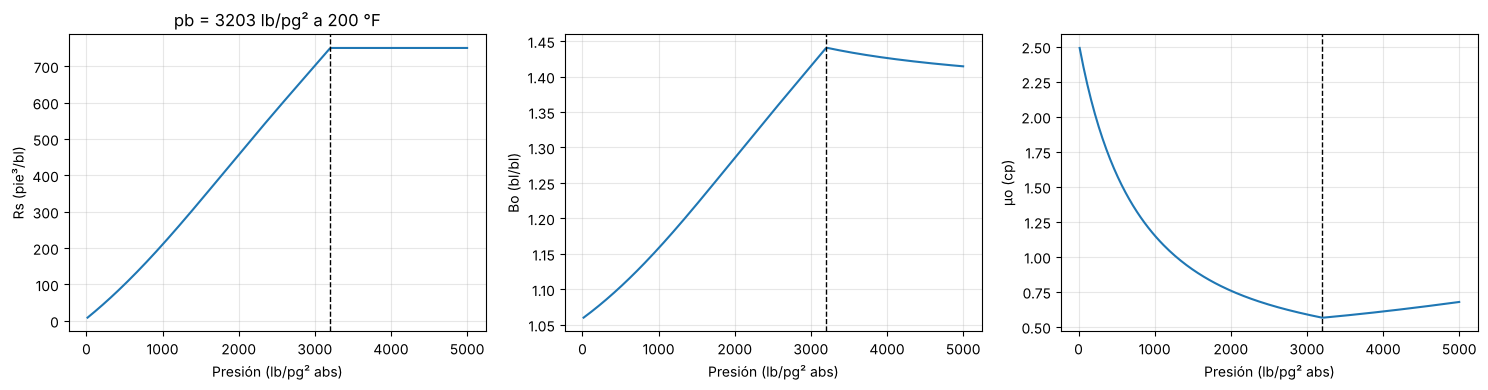

In [10]:
ps = np.linspace(15, 5000, 200)
pb = aceite.pb(200)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].plot(ps, [aceite.rs(p, 200) for p in ps]); axs[0].set(ylabel="Rs (pie³/bl)")
axs[1].plot(ps, [aceite.bo(p, 200) for p in ps]); axs[1].set(ylabel="Bo (bl/bl)")
axs[2].plot(ps, [aceite.viscosidad(p, 200) for p in ps]); axs[2].set(ylabel="μo (cp)")
for ax in axs:
    ax.axvline(pb, ls="--", c="k", lw=1)
    ax.set(xlabel="Presión (lb/pg² abs)"); ax.grid(alpha=0.3)
axs[0].set_title(f"pb = {pb:.0f} lb/pg² a 200 °F")
plt.tight_layout(); plt.show()

## 1.7 Ajustes pVT a las condiciones de separación

La liberación diferencial del laboratorio representa el yacimiento y la prueba de separador (instantánea) representa el
paso por la superficie. Para obtener propiedades a condiciones del separador:

$$B_{of} = B_{ofb}\\,\\frac{B_{od}}{B_{odb}}\\qquad(1.91)\\qquad\\qquad R_{sf} = R_{sfb} - (R_{sdb}-R_{sd})\\,\\frac{B_{ofb}}{B_{odb}}\\qquad(1.92)$$

**Ejercicio con datos ilustrativos** (no son del libro): una liberación diferencial con $B_{odb}$ = 1.52 y $R_{sdb}$ = 820 pie³/bl,
y una prueba de separador con $B_{ofb}$ = 1.455 y $R_{sfb}$ = 750 pie³/bl.

In [11]:
from ductos.pvt_aceite import bo_flash, rs_flash
dif = pd.DataFrame({"p": [3300, 2500, 1500, 500],
                    "Bod": [1.520, 1.430, 1.300, 1.170],
                    "Rsd": [820, 640, 400, 150]})
dif["Bof (Ec. 1.91)"] = [bo_flash(1.455, b, 1.520) for b in dif["Bod"]]
dif["Rsf (Ec. 1.92)"] = [rs_flash(750, 820, r, 1.455, 1.520) for r in dif["Rsd"]]
dif.round(4)

,p,Bod,Rsd,Bof (Ec. 1.91),Rsf (Ec. 1.92)
0,3300,1.52,820,1.4550,750.0000
1,2500,1.43,640,1.3688,577.6974
2,1500,1.30,400,1.2444,347.9605
3,500,1.17,150,1.1200,108.6513


Los datos de liberación diferencial suelen dar $B_o$ y $R_s$ mayores que los de separador, de modo que usarlos sin convertir
subestima el aceite original y el recuperable en los cálculos de balance de materia.